# Compare Jev with gemini-3.8-flash and llama3.2

How well do four predictors find the IRT parameters of the 722 calibrated released items, judged on the same items?

| Run | Predictor | What it sees | How it answers |
| --- | --- | --- | --- |
| `jev_item` | Jev (`typesafe/jev-1.13` through OpenRouter) | the item alone, without its percent correct | a probability for each value of a fixed scale per parameter |
| `jev_references` | Jev | the item and its reference items, with their percent correct and calibrated parameters | the same |
| `gemini` | the LLM `google/gemini-3.8-flash` through OpenRouter, medium reasoning | the item and its reference items, in the prompts of `predict_item_parameters.ipynb` | a value per parameter |
| `llama` | the LLM `llama3.2` in a local Ollama server, no reasoning | the same prompts | a value per parameter |

All four runs come from the package `timss_math.item_parameter_prediction` and use its default retrieval: `gemini-embedding-001` (768 dimensions) and hybrid search, the 10 most similar calibrated items of the item's grade plus up to 5 of the most similar items with its IRT model and points, with the item's other parts left out.
Jev with reference items sees exactly the reference items that the two LLMs see.
The LLM runs are the `gemini-embedding-001` conditions of `predict_item_parameters_compare.ipynb`, read from their saved predictions, and Jev's answers are saved in `data/cache/parameter_predictions/timss_math/openrouter/typesafe_jev-1.13/`.

Two baselines need neither an LLM nor Jev: the calibration-summary mean (the mean of the parameter over the calibrated items of the item's grade with its model and points, its parts left out) and the reference-item mean (the mean over its reference items with its model and points).

1. Build the four runs and check that every prediction is saved.
2. Request missing Jev answers (none by default).
3. Combine the runs and the baselines on the items every run predicted (`RunComparison`).
4. Compare them: mean absolute error, bias, correlation, paired tests, and agreement on the value scales.
5. Compare Jev's point predictions under three estimators, and check whether the spread of its answers tells which predictions are uncertain.
6. Draw the graphs, and export everything to `data/timss_math_predicted_item_parameters_compare_jev.xlsx`.

Run it with its own folder as the working directory, VS Code's default; `DATA_DIR` is `notebooks/data/`.
With every answer and prediction saved, it makes no API call.

In [1]:
import logging
from pathlib import Path

import pandas as pd
from IPython.display import display

from timss_math.item_parameter_prediction import (
    ItemIndex,
    JevPredictor,
    LeaveOneOut,
    LLMPredictor,
    LLMSettings,
    RunComparison,
    plots,
)
from timss_math.item_parameter_prediction.evaluation import correlation
from timss_math.item_parameter_prediction.jev import ESTIMATORS

# The modules report their progress through logging; one line per HTTP request would be too many.
logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)
for name in ("httpx", "httpx2"):
    logging.getLogger(name).setLevel(logging.WARNING)

# The plots module draws matplotlib Figures without pyplot, so the inline backend must be turned on to show them.
%matplotlib inline

DATA_DIR = Path.cwd() / "data"
WORKBOOK = DATA_DIR / "timss_math_predicted_item_parameters_compare_jev.xlsx"

## The four runs

`ItemIndex.build` with its defaults uses `gemini-embedding-001` and the item embeddings that `predict_item_parameters.ipynb` cached in `data/timss_math_item_embeddings.npz`, so it embeds nothing; the collection stays in memory, so it never meets the lock of a local Qdrant store.
Every predictor searches it by hybrid search, its default, and each `LeaveOneOut` finds the predictions saved for its inputs in `data/cache/parameter_predictions/timss_math/<provider>/<model>/`.
The LLM settings are those of `predict_item_parameters_compare.ipynb`; to predict missing LLM items, run the request cell of that notebook.

`JevPredictor` asks Jev one score question per parameter, whose criteria are the values of a scale (`DEFAULT_VALUE_SCALES`), and Jev answers each with a probability for each value.
What Jev sees (the state) is the item's fields without its ID, percent correct, or parameters, and the name of its calibration; with reference items, the state also lists them, and each question's instructions end with a sentence that explains them.
The GPCM steps are defined as TIMSS scales them, θ − b + d<sub>k</sub>, so that scores k − 1 and k are equally likely at θ = b − d<sub>k</sub>, as in the LLMs' system prompt; the three 3-point items are also asked about step 2.
Jev's point prediction is the probability-weighted mean of the values (`estimator="eap"`, the default); the section on estimators compares it with the median and the most likely value.

The cell counts each run's saved predictions and shows what Jev is asked about the first GPCM item, with reference items.

In [2]:
LLMS = {
    "gemini": LLMSettings(),  # google/gemini-3.8-flash through OpenRouter, medium reasoning effort
    "llama": LLMSettings(provider="ollama", model="llama3.2", reasoning_effort=None, max_tokens=4096),
}
JEV_RUNS = ["jev_item", "jev_references"]

index = ItemIndex.build(data_dir=DATA_DIR)  # gemini-embedding-001
predictors = {
    "jev_item": JevPredictor(index, with_references=False),
    "jev_references": JevPredictor(index),
    **{run: LLMPredictor(index, llm) for run, llm in LLMS.items()},
}
loos = {run: LeaveOneOut(predictor, data_dir=DATA_DIR) for run, predictor in predictors.items()}

status = pd.DataFrame({run: loo.status().value_counts() for run, loo in loos.items()}).T.fillna(0).astype(int)
display(status.rename_axis("run"))
if not (status.columns == ["saved"]).all():
    print("Some items have no saved prediction; they are left out of the comparison")

# What Jev is asked about the first GPCM item, with reference items
bank = index.bank
gpcm_key = bank.calibrated.index[bank.calibrated["irt_model"] == "GPCM"][0]
prepared = loos["jev_references"].prepared[gpcm_key]
print(f"{gpcm_key}: {len(prepared['state']['reference_items'])} reference items")
for name, question in prepared["questions"].items():
    print(f"{name}: {question.instructions}")
    print("  " + " | ".join(question.criteria))

728 texts already embedded, 0 to embed
Stored 728 items, 722 with parameters, in collection 'timss_math_items'
Prepared 722 items in 0 s
Prepared 722 items in 16 s
Prepared 722 items in 18 s
Prepared 722 items in 17 s


status,saved
run,
jev_item,722
jev_references,722
gemini,722
llama,722


TIMSS 1995/grade 4/Mathematics/V4A: 14 reference items
slope: TIMSS scaled this 2-point item with the generalized partial credit model (GPCM), which TIMSS uses for constructed-response items worth 2 or 3 points, in the calibration "Concurrent calibration of the TIMSS 1995 and 2003 fourth-grade mathematics data". What is the item's slope (discrimination) parameter a? A higher a means that the item separates students of lower and higher mathematics ability more sharply. Choose the value closest to it. The state also lists reference items: the calibrated TIMSS items of the same grade most similar to this one (never the item itself or its other parts), most similar first, with their percent correct and their calibrated parameters, each on the scale of its own calibration. Use them to place this item.
  0.4 | 0.6 | 0.8 | 1.0 | 1.2 | 1.4 | 1.6 | 1.8 | 2.0 (high discrimination)
location: TIMSS scaled this 2-point item with the generalized partial credit model (GPCM), which TIMSS uses for cons

## Request missing Jev answers

`JEV_MAX_REQUESTS` caps the items requested per Jev run; at 0, the default, the cell requests nothing and the comparison uses the saved answers.
Set it to 1 for a test request, or `None` for every item without a saved answer.
Jev's output is free and its input costs about $0.042 per million tokens: all 722 items cost about $0.036 alone and $0.20 with reference items, and 8 requests at a time answer 55 items in about 2 seconds.

Each answer is saved as soon as it arrives if every question has a probability for each criterion that sum to about 1; otherwise the item is requested again on the next run.
Only HTTP 429 (rate limit), which OpenRouter does not bill, is retried, so no answer is paid for twice.

In [3]:
JEV_MAX_REQUESTS = 0  # items per Jev run; None requests every item without a saved answer

for run in JEV_RUNS:
    report = await loos[run].request_async(JEV_MAX_REQUESTS)
    print(f"{run}: requested {report.requested} items and saved {report.saved} answers for ${report.cost_usd:.4f}")
    for key, error in report.unusable.items():
        print(f"  {key}: {error}")

results = {run: loo.results() for run, loo in loos.items()}

jev_item: requested 0 items and saved 0 answers for $0.0000
jev_references: requested 0 items and saved 0 answers for $0.0000


## The four runs on the same items

`RunComparison` stacks the four runs and the two baselines in `errors`, one row per run, item, and parameter, on the items that every run predicted; a baseline is a run whose prediction is the baseline's value.
It checks that every run has the same calibrated values and calibration-summary means, and takes the reference-item mean from the first run that saw reference items (`jev_references`), since Jev alone saw none.

Step 2 concerns only the three 3-point items, so the comparison leaves it out (`PARAMETERS`).
`wide()` has one row per item and parameter, with every run's prediction side by side.

In [4]:
RUN_LABELS = {
    "jev_item": "Jev 1.13, value scales, item alone",
    "jev_references": "Jev 1.13, value scales, with reference items",
    "gemini": "gemini-3.8-flash, with reference items",
    "llama": "llama3.2, with reference items",
}
PARAMETERS = ["slope", "location", "guessing", "step1"]

comparison = RunComparison(results, labels=RUN_LABELS, parameters=PARAMETERS)
display(comparison.coverage())
wide = comparison.wide()
print(f"{len(wide)} item parameters of {wide['item_key'].nunique()} items:")
display(wide.head(4).round(3))

,items,predicted,in_every_run
run,,,
jev_item,722,722,722
jev_references,722,722,722
gemini,722,722,722
llama,722,722,722


1942 item parameters of 722 items:


,item_key,assessment,grade,item_id,irt_model,parameter,calibrated,calibration_mean,reference_mean,predicted (jev_item),predicted (jev_references),predicted (gemini),predicted (llama),error (jev_item),error (jev_references),error (gemini),error (llama)
0,TIMSS 1995/grade 4/Mathematics/I3,TIMSS 1995,4,I3,3PL,slope,0.927,0.930,1.010,1.112,1.074,1.12,0.863,0.185,0.147,0.193,-0.064
1,TIMSS 1995/grade 4/Mathematics/I3,TIMSS 1995,4,I3,3PL,location,0.111,-0.117,0.003,-0.145,-0.047,0.36,-0.108,-0.256,-0.158,0.249,-0.219
2,TIMSS 1995/grade 4/Mathematics/I3,TIMSS 1995,4,I3,3PL,guessing,0.167,0.195,0.188,0.245,0.214,0.18,0.199,0.078,0.047,0.013,0.032
3,TIMSS 1995/grade 4/Mathematics/I4,TIMSS 1995,4,I4,3PL,slope,1.243,0.928,0.975,1.234,0.972,0.94,0.600,-0.009,-0.271,-0.303,-0.643


## Prediction error

The mean absolute error of each run and baseline per parameter, then by grade.
A useful predictor beats the calibration-summary mean, which needs neither retrieval nor a predictor, and the reference-item mean, which needs retrieval only.
The summary adds, per run, the bias (`mean_error`, predicted minus calibrated), the spread of the errors, the RMSE, and the Pearson and Spearman correlations of the predicted with the calibrated values.
A predictor that gives (almost) the same value to every item, as the calibration-summary mean does within a grade and model, can have a small error and a correlation near 0.
The calibration-summary mean leaves the item's parts out, so within a grade and model it is a little lower for an item with a higher value, which makes its Spearman correlation meaningless (such as −0.74 for guessing).

In [5]:
mae = comparison.mae()
print(f"Mean absolute error on the {len(comparison.common_items)} items every run predicted:")
display(mae.round(3))
print("By grade:")
display(comparison.mae("grade").round(3))
print("Bias, spread, and correlation of each run and baseline:")
display(comparison.summary().round(3))

Mean absolute error on the 722 items every run predicted:


,items,jev_item,jev_references,gemini,llama,calibration_mean,reference_mean
parameter,,,,,,,
slope,722,0.315,0.224,0.214,0.310,0.245,0.230
location,722,0.681,0.501,0.393,0.650,0.541,0.527
guessing,442,0.071,0.059,0.056,0.084,0.058,0.060
step1,56,0.834,0.792,0.755,1.196,0.774,0.865


By grade:


items  jev_item  jev_references  gemini  llama  \
grade parameter                                                   
4     slope        295     0.326           0.206   0.202  0.283   
      location     295     0.694           0.528   0.417  0.731   
      guessing     164     0.068           0.054   0.052  0.080   
      step1         18     0.960           0.878   0.736  1.062   
8     slope        356     0.293           0.234   0.225  0.318   
      location     356     0.691           0.476   0.366  0.585   
      guessing     234     0.070           0.061   0.056  0.086   
      step1         30     0.745           0.775   0.828  1.340   
12    slope         71     0.379           0.243   0.210  0.382   
      location      71     0.580           0.514   0.431  0.636   
      guessing      44     0.081           0.072   0.067  0.092   
      step1          8     0.884           0.665   0.524  0.953   
all   slope        722     0.315           0.224   0.214  0.310   
      location     722     0.681           0.501   0.393  0.650   
      guessing     442     0.071           0.059   0.056  0.084   
      step1         56     0.834           0.792   0.755  1.196   

                 calibration_mean  reference_mean  
grade parameter                                    
4     slope                 0.220           0.215  
      location              0.617           0.584  
      guessing              0.053           0.053  
      step1                 0.961           1.096  
8     slope                 0.269           0.243  
      location              0.486           0.483  
      guessing              0.060           0.062  
      step1                 0.743           0.832  
12    slope                 0.235           0.227  
      location              0.500           0.510  
      guessing              0.071           0.071  
      step1                 0.468           0.468  
all   slope                 0.245           0.230  
      location              0.541           0.527  
      guessing              0.058           0.060  
      step1                 0.774           0.865

Bias, spread, and correlation of each run and baseline:


items  mean_error  sd_error    mae   rmse  \
parameter run                                                           
slope     jev_item            722       0.195     0.331  0.315  0.384   
          jev_references      722       0.037     0.284  0.224  0.286   
          gemini              722       0.046     0.271  0.214  0.275   
          llama               722       0.063     0.406  0.310  0.410   
          calibration_mean    722      -0.000     0.311  0.245  0.310   
          reference_mean      722       0.017     0.296  0.230  0.296   
location  jev_item            722      -0.511     0.648  0.681  0.825   
          jev_references      722      -0.208     0.603  0.501  0.638   
          gemini              722      -0.060     0.505  0.393  0.508   
          llama               722      -0.012     0.845  0.650  0.844   
          calibration_mean    722      -0.000     0.684  0.541  0.684   
          reference_mean      722       0.007     0.674  0.527  0.674   
guessing  jev_item            442       0.042     0.073  0.071  0.085   
          jev_references      442       0.014     0.073  0.059  0.074   
          gemini              442      -0.015     0.072  0.056  0.073   
          llama               442      -0.023     0.113  0.084  0.115   
          calibration_mean    442       0.000     0.074  0.058  0.074   
          reference_mean      442       0.001     0.077  0.060  0.077   
step1     jev_item             56       0.179     1.000  0.834  1.007   
          jev_references       56       0.064     0.980  0.792  0.973   
          gemini               56       0.165     0.952  0.755  0.958   
          llama                56       0.399     1.425  1.196  1.467   
          calibration_mean     56      -0.003     0.954  0.774  0.946   
          reference_mean       56      -0.038     1.064  0.865  1.055   

                            pearson  spearman  
parameter run                                  
slope     jev_item            0.146     0.142  
          jev_references      0.529     0.530  
          gemini              0.586     0.580  
          llama               0.253     0.312  
          calibration_mean    0.370     0.157  
          reference_mean      0.480     0.481  
location  jev_item            0.491     0.475  
          jev_references      0.554     0.548  
          gemini              0.719     0.717  
          llama               0.218     0.220  
          calibration_mean    0.323     0.084  
          reference_mean      0.376     0.365  
guessing  jev_item            0.120     0.091  
          jev_references      0.184     0.199  
          gemini              0.230     0.248  
          llama              -0.098    -0.094  
          calibration_mean   -0.035    -0.743  
          reference_mean      0.087     0.096  
step1     jev_item           -0.271    -0.281  
          jev_references      0.157     0.212  
          gemini              0.384     0.298  
          llama               0.022    -0.006  
          calibration_mean    0.251    -0.042  
          reference_mean      0.048     0.010

## Paired comparisons

Every item's parameter has an absolute error in each run, so the runs are compared on the same items: for a pair of runs, the per-item difference of their absolute errors (first minus second), with its mean, standard error, 95% confidence interval, and the p-value of a paired t-test.
A negative estimate means that the first run predicts better.
Every pair of the four runs is compared, and every run with each baseline; `p_holm` adjusts the p-values for the 14 comparisons of each parameter (Holm).
The test treats the items as independent, although the parts of a multi-part item, and the items of one task, are not, so the p-values are somewhat too small.

In [6]:
paired = comparison.paired()
display(paired.round({"estimate": 3, "se": 3, "t": 2, "p_value": 4, "p_holm": 4, "ci_low": 3, "ci_high": 3}))

items  estimate     se      t  \
parameter comparison                                                         
slope     jev_item − jev_references            722     0.091  0.007  12.69   
          jev_item − gemini                    722     0.101  0.007  13.97   
          jev_item − llama                     722     0.005  0.011   0.45   
          jev_references − gemini              722     0.010  0.004   2.66   
          jev_references − llama               722    -0.086  0.009  -9.41   
          gemini − llama                       722    -0.096  0.009 -10.48   
          jev_item − calibration_mean          722     0.069  0.007   9.41   
          jev_item − reference_mean            722     0.084  0.008  10.88   
          jev_references − calibration_mean    722    -0.022  0.006  -3.89   
          jev_references − reference_mean      722    -0.007  0.005  -1.46   
          gemini − calibration_mean            722    -0.031  0.005  -6.15   
          gemini − reference_mean              722    -0.016  0.004  -4.19   
          llama − calibration_mean             722     0.065  0.010   6.71   
          llama − reference_mean               722     0.080  0.009   8.55   
location  jev_item − jev_references            722     0.180  0.014  13.29   
          jev_item − gemini                    722     0.288  0.017  17.35   
          jev_item − llama                     722     0.032  0.025   1.28   
          jev_references − gemini              722     0.108  0.011   9.77   
          jev_references − llama               722    -0.148  0.020  -7.31   
          gemini − llama                       722    -0.256  0.019 -13.72   
          jev_item − calibration_mean          722     0.140  0.020   7.01   
          jev_item − reference_mean            722     0.155  0.020   7.68   
          jev_references − calibration_mean    722    -0.040  0.015  -2.74   
          jev_references − reference_mean      722    -0.026  0.014  -1.84   
          gemini − calibration_mean            722    -0.148  0.013 -11.36   
          gemini − reference_mean              722    -0.133  0.012 -10.77   
          llama − calibration_mean             722     0.109  0.018   6.18   
          llama − reference_mean               722     0.123  0.018   6.99   
guessing  jev_item − jev_references            442     0.011  0.001   7.75   
          jev_item − gemini                    442     0.015  0.002   6.09   
          jev_item − llama                     442    -0.013  0.004  -3.32   
          jev_references − gemini              442     0.004  0.002   2.40   
          jev_references − llama               442    -0.025  0.003  -7.19   
          gemini − llama                       442    -0.028  0.003  -8.94   
          jev_item − calibration_mean          442     0.013  0.002   6.58   
          jev_item − reference_mean            442     0.011  0.002   5.04   
          jev_references − calibration_mean    442     0.001  0.001   0.94   
          jev_references − reference_mean      442    -0.001  0.001  -0.38   
          gemini − calibration_mean            442    -0.003  0.001  -2.24   
          gemini − reference_mean              442    -0.004  0.001  -2.94   
          llama − calibration_mean             442     0.026  0.003   7.98   
          llama − reference_mean               442     0.024  0.003   7.26   
step1     jev_item − jev_references             56     0.042  0.043   0.99   
          jev_item − gemini                     56     0.079  0.083   0.96   
          jev_item − llama                      56    -0.362  0.120  -3.01   
          jev_references − gemini               56     0.037  0.069   0.54   
          jev_references − llama                56    -0.404  0.121  -3.34   
          gemini − llama                        56    -0.441  0.121  -3.65   
          jev_item − calibration_mean           56     0.060  0.054   1.12   
          jev_item − reference_mean             56    -0.031  0.064

## Agreement on the value scales

The scales also give a categorical view: for each item and parameter, the value Jev picks (its most likely one) and, for the two LLMs, the value of the scale closest to their prediction, against the value closest to the calibrated parameter.
`exact` is the share of items whose value is the calibrated one, `within_one` the share within one step of the scale, and `weighted_kappa` the quadratic weighted kappa; the baseline is the best constant value, the one that is exact (or within one) for the most items.
The scales are uneven (the location's steps run from 0.2 to 1.0), so a step is not the same distance everywhere.

`value_spread` counts how often each value is picked: a predictor that ignores the item picks one value for almost every item.

In [7]:
agreement = comparison.scale_agreement()
percent = "{:.1%}"
print("Agreement with the calibrated parameters' closest scale values")
display(
    agreement.style.format(
        {column: percent for column in agreement.columns if "exact" in column or "within" in column}
        | {column: "{:.3f}" for column in agreement.columns if "kappa" in column}
    )
)
print("By grade:")
display(comparison.scale_agreement("grade").round(3))
print("How often each value is picked (the calibrated column counts the calibrated parameters' closest values)")
display(comparison.value_spread())

Agreement with the calibrated parameters' closest scale values


,items,jev_item_exact,jev_item_within_one,jev_item_weighted_kappa,jev_references_exact,jev_references_within_one,jev_references_weighted_kappa,gemini_exact,gemini_within_one,gemini_weighted_kappa,llama_exact,llama_within_one,llama_weighted_kappa,baseline_exact,baseline_within_one
parameter,,,,,,,,,,,,,,,
slope,722,21.2%,62.7%,-0.004,25.3%,65.8%,0.433,30.2%,72.7%,0.498,19.1%,58.0%,0.255,25.2%,62.6%
location,722,12.0%,38.5%,0.256,19.8%,52.1%,0.436,28.5%,68.1%,0.633,15.2%,46.3%,0.219,16.5%,48.3%
guessing,442,24.4%,61.5%,0.039,24.4%,66.3%,0.070,29.2%,78.7%,0.167,23.5%,62.2%,-0.071,26.9%,77.1%
step1,56,8.9%,53.6%,0.007,25.0%,58.9%,0.236,23.2%,58.9%,0.238,14.3%,41.1%,0.008,25.0%,53.6%


By grade:


items  jev_item_exact  jev_item_within_one  \
parameter grade                                               
slope     4        295           0.186                0.661   
          8        356           0.225                0.610   
          12        71           0.254                0.577   
location  4        295           0.159                0.434   
          8        356           0.101                0.346   
          12        71           0.056                0.380   
guessing  4        164           0.256                0.604   
          8        234           0.244                0.632   
          12        44           0.205                0.568   
step1     4         18           0.056                0.389   
          8         30           0.100                0.567   
          12         8           0.125                0.750   

                 jev_item_weighted_kappa  jev_references_exact  \
parameter grade                                                  
slope     4                       -0.004                 0.292   
          8                        0.015                 0.233   
          12                      -0.108                 0.197   
location  4                        0.223                 0.220   
          8                        0.203                 0.194   
          12                       0.186                 0.127   
guessing  4                        0.011                 0.262   
          8                        0.057                 0.239   
          12                      -0.016                 0.205   
step1     4                        0.000                 0.389   
          8                        0.022                 0.167   
          12                       0.000                 0.250   

                 jev_references_within_one  jev_references_weighted_kappa  \
parameter grade                                                             
slope     4                          0.732                          0.448   
          8                          0.601                          0.380   
          12                         0.634                          0.326   
location  4                          0.553                          0.396   
          8                          0.503                          0.365   
          12                         0.479                          0.284   
guessing  4                          0.683                          0.104   
          8                          0.667                          0.064   
          12                         0.568                         -0.016   
step1     4                          0.611                          0.352   
          8                          0.567                          0.149   
          12                         0.625                         -0.356   

                 gemini_exact  gemini_within_one  gemini_weighted_kappa  \
parameter grade                                                           
slope     4             0.278              0.769                  0.419   
          8             0.329              0.688                  0.462   
          12            0.268              0.746                  0.472   
location  4             0.308              0.725                  0.636   
          8             0.275              0.680                  0.602   
          12            0.239              0.507                  0.404   
guessing  4             0.299              0.799                  0.124   
          8             0.303              0.786                  0.182   
          12            0.205              0.750                  0.168   
step1     4             0.389              0.667                  0.234   
          8             0.067              0.500                 -0.152   
          12            0.500              0.750                 -0.290   

                 llama_exact  llama_within_one  llama_weighted_kappa  \
paramet

How often each value is picked (the calibrated column counts the calibrated parameters' closest values)


calibrated  jev_item  jev_references  gemini  llama
parameter value                                                     
slope      0.40          45         1              13       2     27
           0.60         112         0              74      41     78
           0.80         182         0             211     191    156
           1.00         150       705             196     222    191
           1.20         120         7             147     214    125
           1.40          66         9              58      47    109
           1.60          26         0              15       5     16
           1.80          11         0               3       0      8
           2.00          10         0               5       0     12
location  -2.00          17        74              15       0      9
          -1.00          58       204              84      43     46
          -0.50         113       142             177     117     94
           0.00         117       250             111     139    149
           0.20         119         0             102     202    152
           0.50         110        39             147     150    138
           0.80          81        12              54      59     73
           1.00          70         1              29      11     47
           1.50          32         0               3       1     13
           2.00           5         0               0       0      1
guessing   0.00           5         0               0       0     25
           0.10          72         0               6       2     87
           0.15         119         0              33     182    102
           0.20         113        82             123     251    156
           0.25         109       360             280       7     64
           0.40          24         0               0       0      8
step1     -3.00           2         0               1       0      1
          -2.00           8         0               5       0      5
          -1.50          14         0              13      14      9
          -1.00           5        54              11      19     11
          -0.50          11         2              18      11      5
           0.00          13         0               8       8     15
           1.00           2         0               0       4      9
           2.00           1         0               0       0      1

## Jev's point predictions and their spread

Jev's probabilities over the values of a scale are a discrete distribution of the parameter, so its point prediction is a choice of estimator, made when the saved answers are read, with no new request:

- `eap`, the probability-weighted mean (expected a posteriori), minimizes the expected squared error; it is the point prediction above.
- `median`, the value at which the cumulative probability reaches 0.5, minimizes the expected absolute error, the error compared here.
- `map`, the most likely value (maximum a posteriori), is the value that the agreement above counts.

The first table gives the mean absolute error and the bias of each estimator.
The second asks whether the spread of Jev's answers (`sd`, the standard deviation of the distribution) tells which predictions are uncertain: the Spearman correlation of the spread with the absolute error of the EAP, which is positive if the items Jev is less sure of are predicted worse.

In [8]:
jev_rows = comparison.errors[comparison.errors["run"].isin(JEV_RUNS)].copy()
jev_rows["run"] = jev_rows["run"].astype(str)
estimators = pd.concat(
    {
        estimator: jev_rows.assign(error=jev_rows[estimator] - jev_rows["calibrated"])
        .groupby(["parameter", "run"], observed=True)["error"]
        .agg(mae=lambda error: error.abs().mean(), mean_error="mean")
        for estimator in ESTIMATORS
    },
    axis=1,
)
print("Mean absolute error and bias of Jev's point predictions under each estimator:")
display(estimators.round(3))

spread = (
    jev_rows.groupby(["parameter", "run"], observed=True)
    .apply(
        lambda rows: pd.Series(
            {
                "items": len(rows),
                "mean_sd": rows["sd"].mean(),
                "spearman_sd_abs_error": correlation(rows["sd"], (rows["eap"] - rows["calibrated"]).abs(), "spearman"),
                "spearman_confidence_abs_error": correlation(
                    rows["confidence"], (rows["eap"] - rows["calibrated"]).abs(), "spearman"
                ),
            }
        )
    )
    .astype({"items": int})
)
print("Does the spread of Jev's answers, or its confidence, go with larger errors?")
display(spread.round(3))

Mean absolute error and bias of Jev's point predictions under each estimator:


eap            median               map           
                            mae mean_error    mae mean_error    mae mean_error
parameter run                                                                 
slope     jev_item        0.315      0.195  0.309      0.187  0.270      0.038
          jev_references  0.224      0.037  0.236      0.018  0.249      0.017
location  jev_item        0.681     -0.511  0.670     -0.472  0.834     -0.709
          jev_references  0.501     -0.208  0.515     -0.164  0.574     -0.209
guessing  jev_item        0.071      0.042  0.074      0.048  0.074      0.048
          jev_references  0.059      0.014  0.065      0.026  0.070      0.034
step1     jev_item        0.834      0.179  0.822     -0.073  0.813     -0.118
          jev_references  0.792      0.064  0.772     -0.024  0.801     -0.073

Does the spread of Jev's answers, or its confidence, go with larger errors?


items  mean_sd  spearman_sd_abs_error  \
parameter run                                                     
slope     jev_item          722    0.371                 -0.001   
          jev_references    722    0.254                  0.069   
location  jev_item          722    0.709                 -0.006   
          jev_references    722    0.588                  0.032   
guessing  jev_item          442    0.033                  0.024   
          jev_references    442    0.052                  0.064   
step1     jev_item           56    1.071                 -0.296   
          jev_references     56    0.907                  0.034   

                          spearman_confidence_abs_error  
parameter run                                            
slope     jev_item                               -0.016  
          jev_references                         -0.053  
location  jev_item                                0.263  
          jev_references                          0.053  
guessing  jev_item                                0.006  
          jev_references                         -0.020  
step1     jev_item                                0.226  
          jev_references                         -0.071

## Graphs

1. The mean absolute error of each run, with the calibration-summary mean as a black line.
2. The mean absolute error by grade, with 95% confidence intervals, and both baselines.
3. Each run's point predictions against the calibrated values, one row per run.
4. How often each run's value is the calibrated parameter's closest value, or within one step of it, against the best constant value.
5. Each run's values against the calibrated values, one row per run: a strong diagonal is accurate.

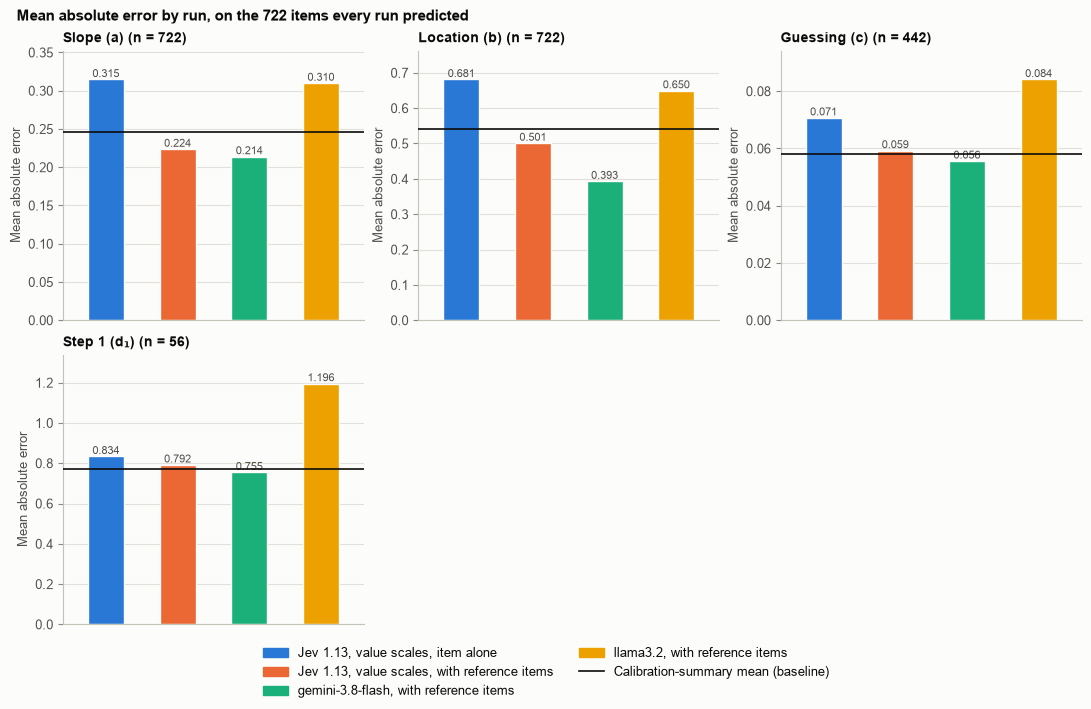

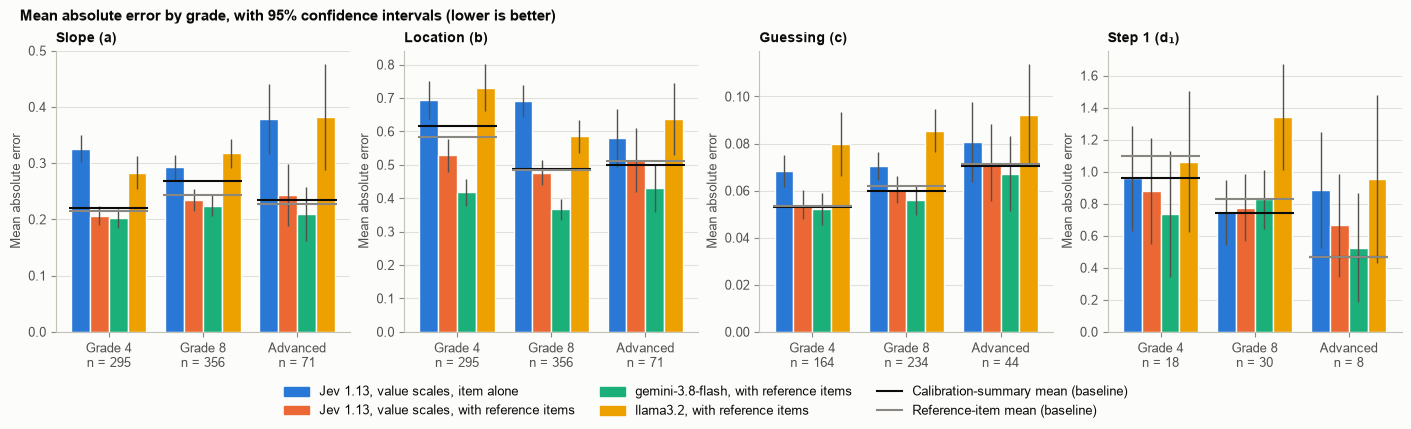

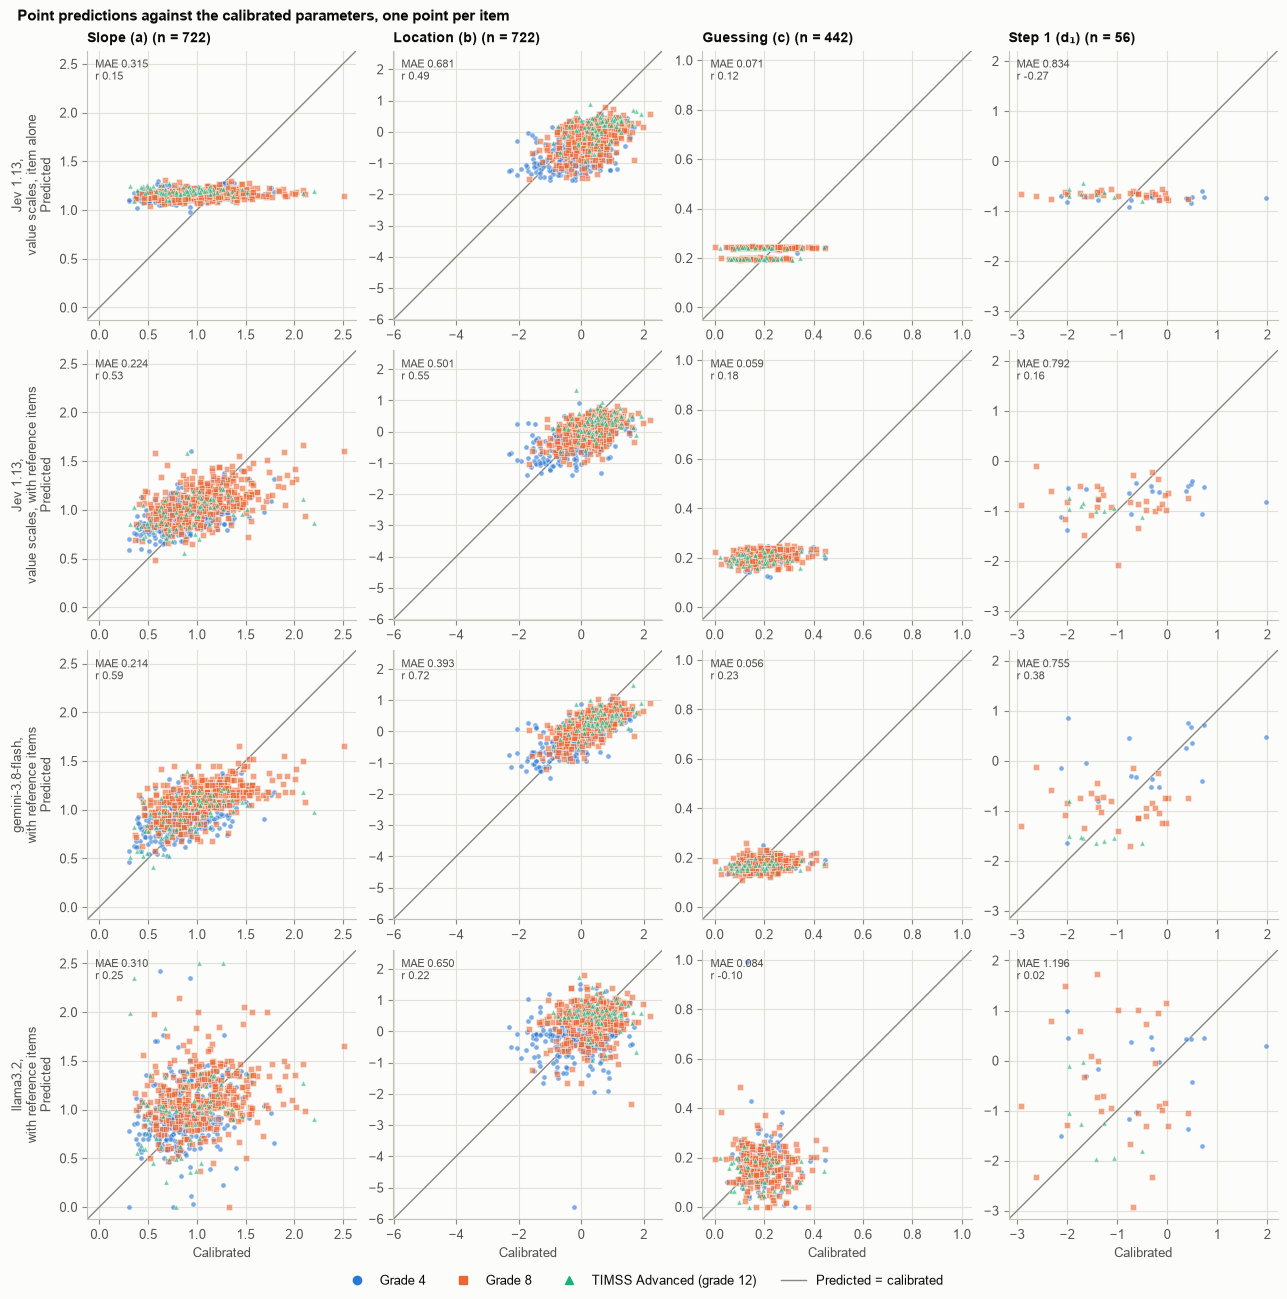

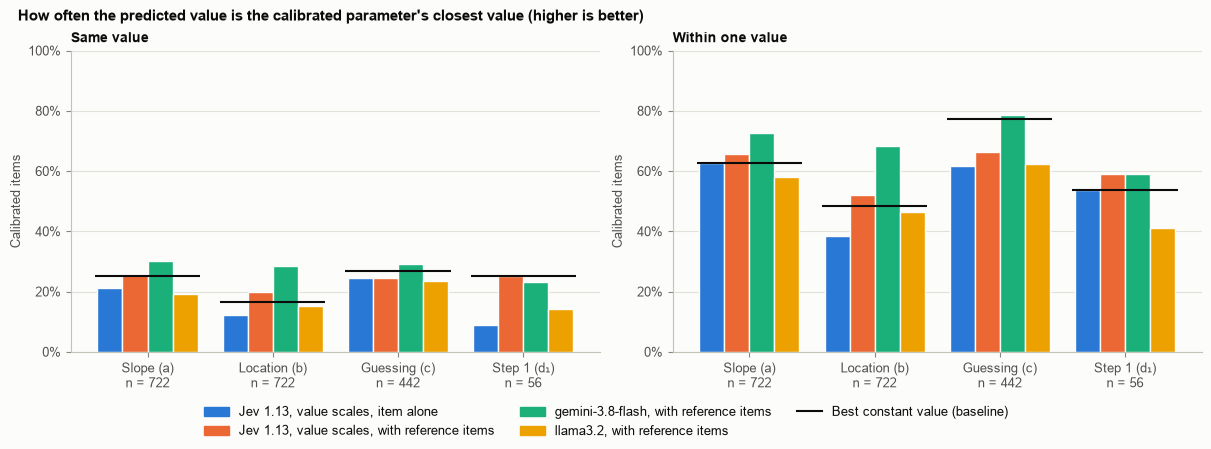

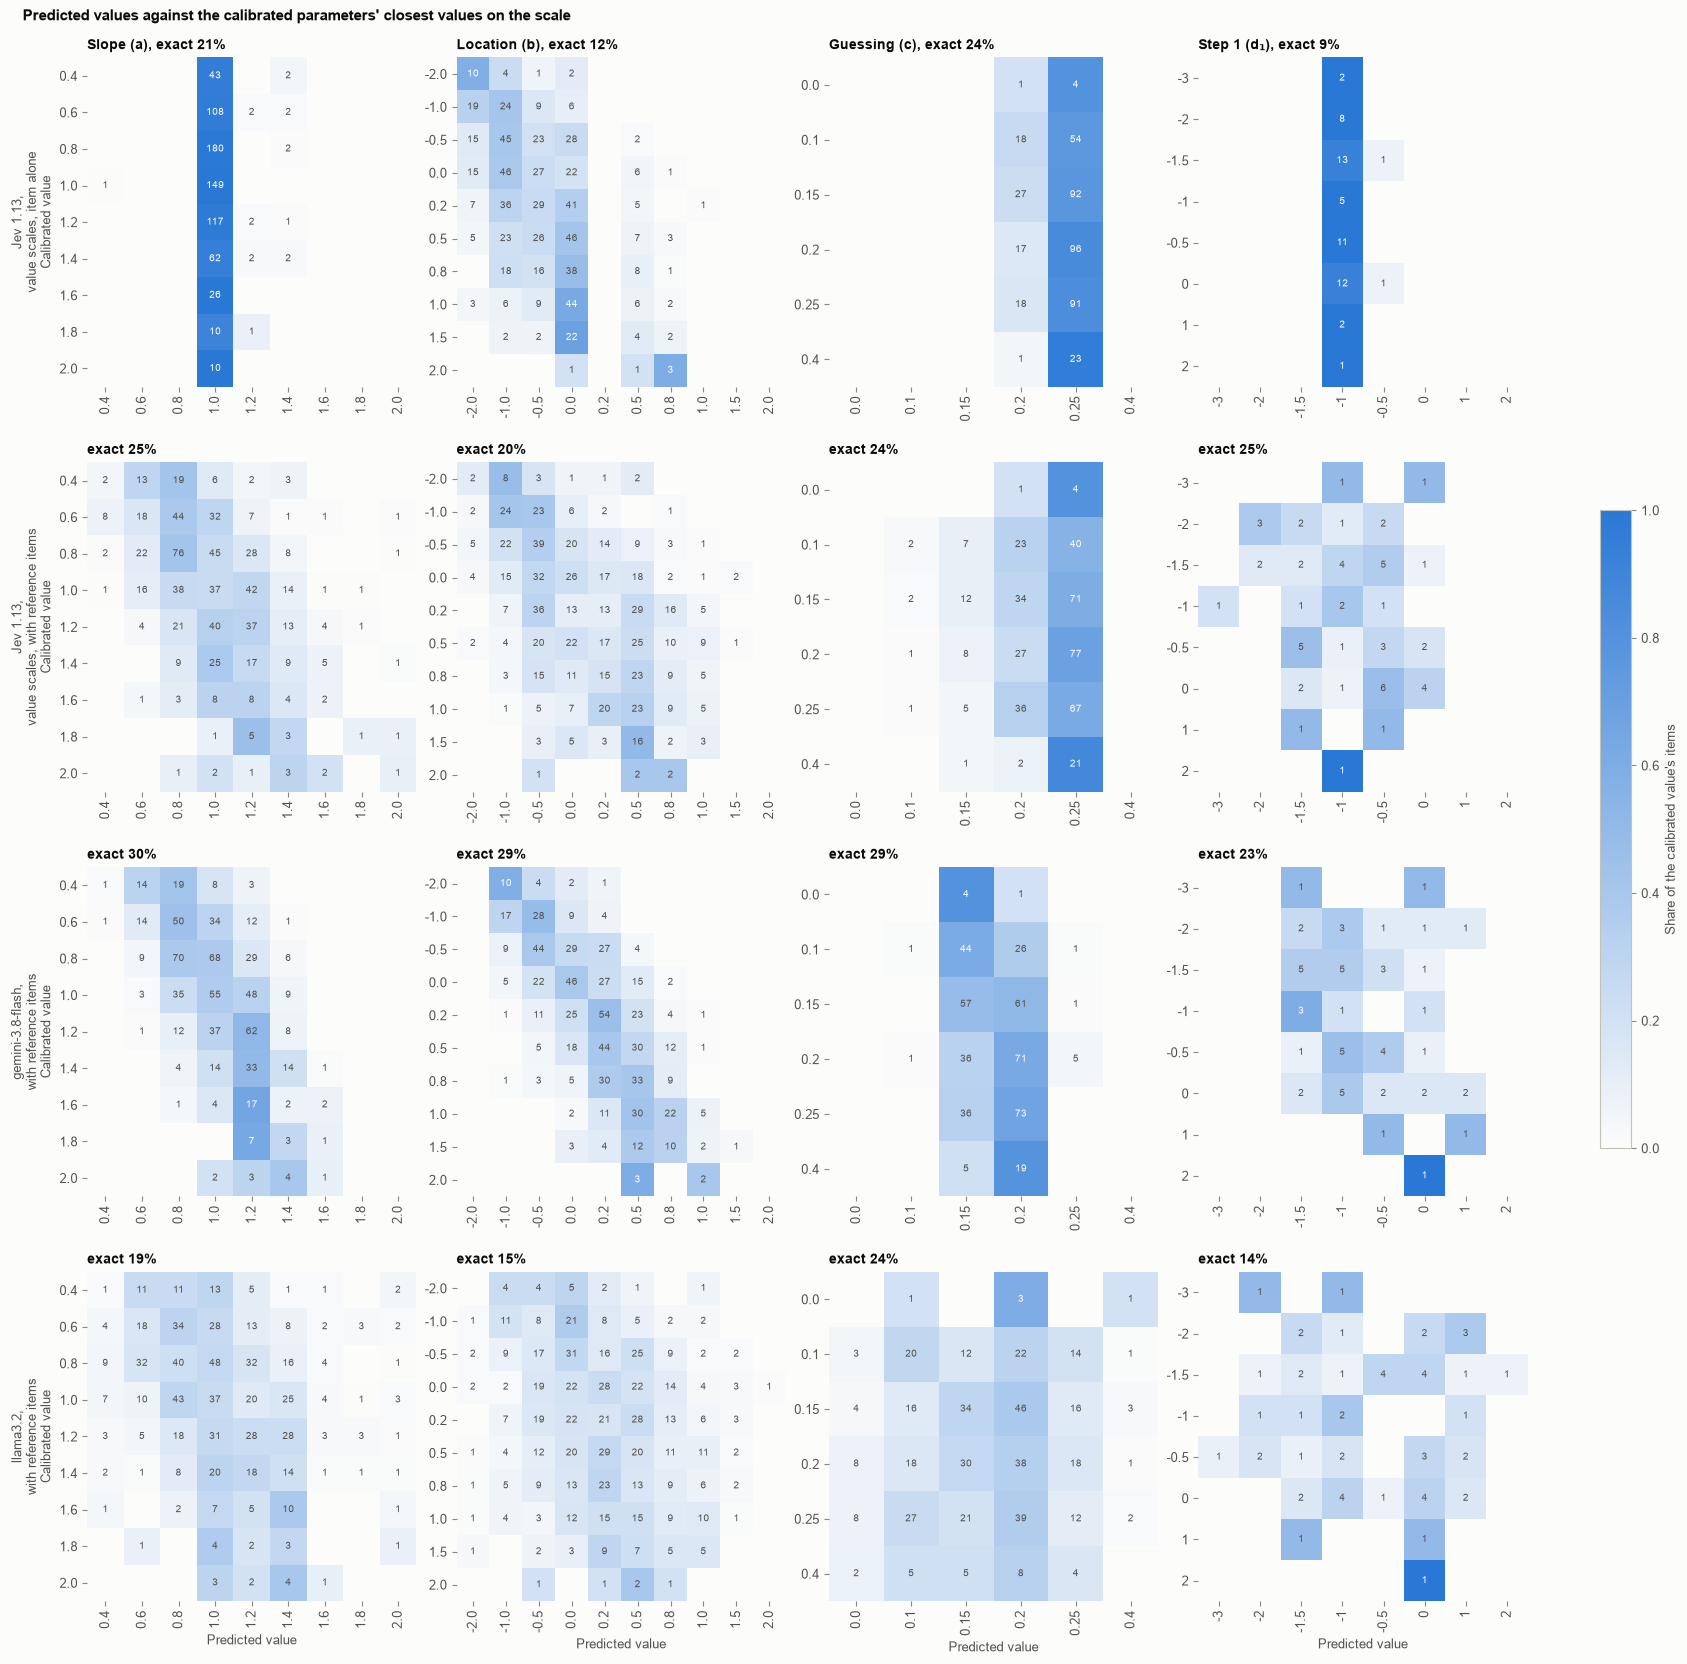

In [9]:
compared = comparison.errors
display(
    plots.compare_runs(
        {RUN_LABELS[run]: compared[compared["run"] == run] for run in comparison.run_names}, parameters=PARAMETERS
    )
)
display(plots.comparison_mae_by_grade(comparison))
display(plots.comparison_predicted_vs_calibrated(comparison))
display(plots.comparison_scale_agreement(comparison))
display(plots.comparison_scale_confusion(comparison))

## Export

`WORKBOOK` (`data/timss_math_predicted_item_parameters_compare_jev.xlsx`, copied to `results/predict_item_parameters_compare_jev.xlsx` in the repository) has one sheet per table:

| Sheet | Contents |
| --- | --- |
| `predictions_wide` | `wide()`: one row per item and parameter, with every run's prediction and error side by side, and the baselines. |
| `prediction_errors` | `errors`: one row per run (and baseline), item, and parameter, with Jev's posterior columns. |
| `jev_posteriors` | Jev's answers alone and with reference items: every estimator's value, the spread, Jev's confidence, and the probabilities of every value. |
| `predictions` | One row per run and item: every parameter predicted and calibrated with its error, the LLMs' reasoning and Jev's answers, usage, and cost, and the file each prediction is saved in. |
| `coverage` | The items each run predicted. |
| `mae`, `mae_by_grade` | The mean absolute error of every run and baseline. |
| `summary` | Bias, spread, MAE, RMSE, and correlations of every run and baseline. |
| `paired_comparisons` | The paired t-tests of the absolute errors. |
| `value_agreement`, `value_agreement_by_grade`, `value_spread` | Agreement on the value scales, and how often each value is picked. |
| `value_choices` | Each run's value and the calibrated parameter's closest value, per item and parameter. |
| `cost` | The tokens and cost of every run, and the median seconds of a request where recorded. |
| `settings` | The settings of every run. |
| `jev_estimators`, `jev_spread` | The two tables of the section on Jev's point predictions. |

In [10]:
comparison.to_excel(WORKBOOK)
with pd.ExcelWriter(WORKBOOK, mode="a", engine="openpyxl") as writer:
    estimators.to_excel(writer, sheet_name="jev_estimators")
    spread.to_excel(writer, sheet_name="jev_spread")
display(comparison.cost().style.format({"cost_usd": "${:.4f}", "cost_per_item_usd": "${:.6f}", "median_seconds": "{:.2f}"}))
print(f"Wrote {WORKBOOK.name}")

,items,input_tokens,output_tokens,cost_usd,cost_per_item_usd,requests_timed,median_seconds
run,,,,,,,
jev_item,722.000000,849970.000000,29396.000000,$0.0357,$0.000049,56.000000,0.20
jev_references,722.000000,4703436.000000,29396.000000,$0.1975,$0.000274,56.000000,0.24
gemini,722.000000,4074035.000000,1463611.000000,$8.5441,$0.011834,0.000000,nan
llama,722.000000,3584201.000000,704306.000000,$nan,$nan,0.000000,nan


Wrote timss_math_predicted_item_parameters_compare_jev.xlsx


### Results on 2026-10-14

Every run predicted all 722 calibrated items, and the notebook requested nothing.
Jev's answers on the 666 dichotomous items are those of `test_jev.ipynb` (2026-10-13); the 56 GPCM items were asked again on 2026-10-14 with the corrected definition of the steps, which changed Jev's step 1 MAE from 0.808 to 0.834 alone and from 0.795 to 0.792 with reference items, and its slope and location MAEs by at most 0.001.
MAE is the mean absolute error, and a p-value is Holm-adjusted (`p_holm`).

| MAE | Jev, item alone | Jev, with reference items | gemini-3.8-flash | llama3.2 | Calibration-summary mean | Reference-item mean |
| --- | --- | --- | --- | --- | --- | --- |
| Slope (722 items) | 0.315 | 0.224 | **0.214** | 0.310 | 0.245 | 0.230 |
| Location (722) | 0.681 | 0.501 | **0.393** | 0.650 | 0.541 | 0.527 |
| Guessing (442) | 0.071 | 0.059 | **0.056** | 0.084 | 0.058 | 0.060 |
| Step 1 (56) | 0.834 | 0.792 | **0.755** | 1.196 | 0.774 | 0.865 |

- gemini-3.8-flash predicts every parameter best. It beats Jev with reference items most on location (by 0.108, p < 0.001), a little on slope (0.010, p = 0.02), and not significantly on guessing (p = 0.07) or step 1 (p = 1.0), and its predictions correlate best with the calibrated values (location r = 0.72, slope 0.59, against 0.55 and 0.53 for Jev with reference items).
- Jev needs the reference items. Alone it picks a slope of 1.0 for 705 of the 722 items and a guessing parameter of 0.25 for 360 of the 442 multiple-choice items (0.20 for the rest), so its slope hardly depends on the item (r = 0.15), and it predicts items too easy (location bias −0.51); it does worse than the calibration-summary mean on slope, location, and guessing (each p < 0.001).
  The reference items lower its MAE by 0.091 on slope, 0.180 on location, and 0.011 on guessing (each p < 0.001).
  With them it beats the calibration-summary mean on slope (by 0.022, p < 0.001) and location (0.040, p = 0.02) but not the reference-item mean (p = 0.29 and 0.13): it does about as well as averaging the reference items scored like the item, and it still predicts items too easy (location bias −0.21).
- llama3.2 does worse than Jev with reference items and gemini-3.8-flash on every parameter (p ≤ 0.02), and worse than the calibration-summary mean on every one.
  Jev alone, which never sees a reference item, is about as good on slope and location (differences of 0.005 and 0.032, p = 0.65 and 0.20), and better on guessing (by 0.013, p = 0.006) and step 1 (by 0.36, p = 0.04).
- On the value scales, gemini-3.8-flash's closest value is within one step of the calibrated parameter's for 73% of the slopes, 68% of the locations, and 79% of the guessing parameters, against 66%, 52%, and 66% for Jev with reference items and 63%, 48%, and 77% for the best constant value; its weighted kappa on location is 0.63, against 0.44 for Jev with reference items, 0.26 for Jev alone, and 0.22 for llama3.2.
- Step 1 has only 56 items, and no run beats the calibration-summary mean on it.
- The probability-weighted mean is Jev's best point prediction with reference items: the median and the most likely value raise its MAE on slope (0.236 and 0.249, against 0.224), location (0.515 and 0.574, against 0.501), and guessing (0.065 and 0.070, against 0.059), although the median would minimize the expected absolute error if Jev's probabilities were the parameter's distribution.
  The spread of Jev's answers hardly tells which predictions are wrong: its Spearman correlation with the absolute error is between −0.01 and 0.07 on slope, location, and guessing; and when Jev sees the item alone, its own confidence goes with larger location errors (0.26).
- Jev is cheap and fast: all 722 items cost $0.036 alone and $0.198 with reference items, as OpenRouter reported, against $8.54 for gemini-3.8-flash as recorded (about $4.50 as OpenRouter batches), and its 56 timed requests per run on 2026-10-14 took a median of 0.20 seconds alone and 0.24 seconds with reference items; llama3.2 costs nothing but takes about 22 seconds per item.